# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [1]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [2]:

def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))


Sąsiedzi startu: [(0, 1)]



## 2. Wizualizacja problemu


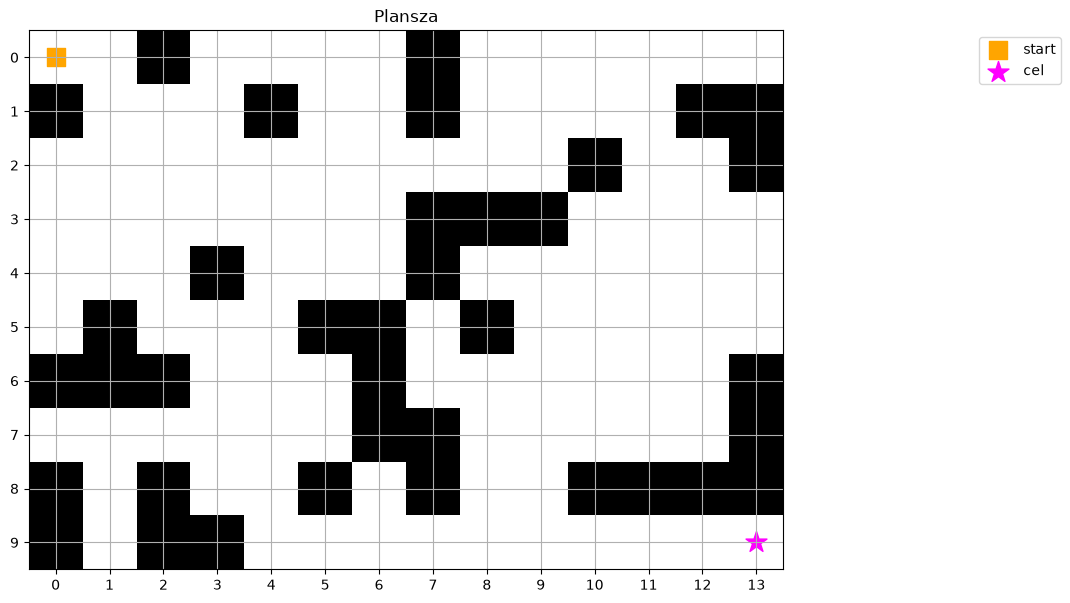

In [3]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


BFS - długość ścieżki:

 22
BFS - odwiedzone stany: 103
BFS - ścieżka: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (5, 2), (5, 3), (6, 3), (7, 3), (8, 3), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


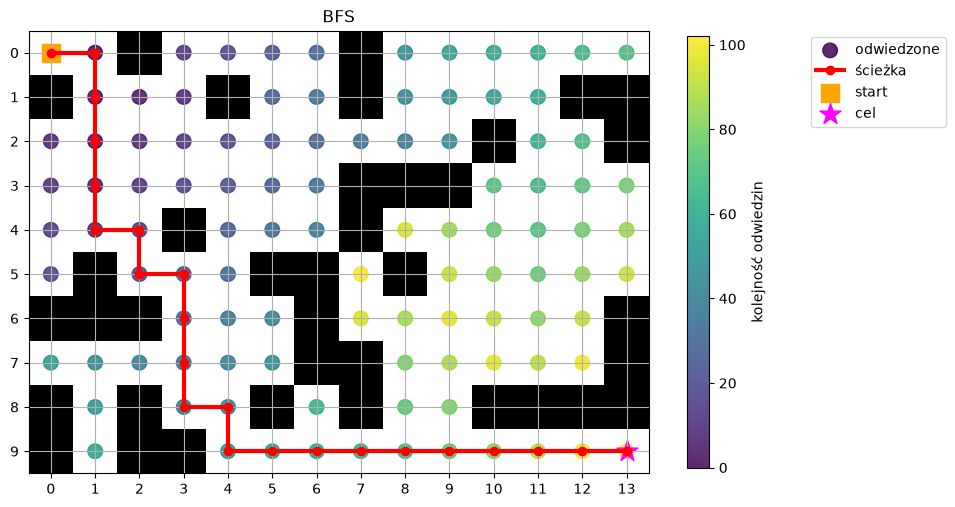

In [4]:

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")



### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?
2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

DFS - długość ścieżki: 42
DFS - odwiedzone stany: 50
DFS - ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (1, 3), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (1, 9), (1, 10), (1, 11), (2, 11), (2, 12), (3, 12), (3, 13), (4, 13), (4, 12), (4, 11), (4, 10), (4, 9), (5, 9), (5, 10), (5, 11), (5, 12), (6, 12), (6, 11), (6, 10), (6, 9), (6, 8), (7, 8), (7, 9), (8, 9), (8, 8), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


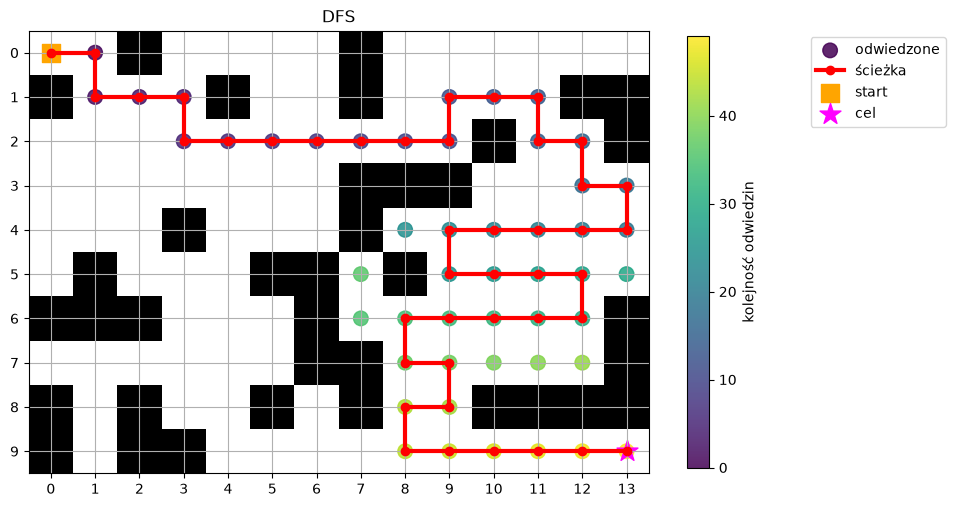

In [5]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [6]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81
(4, 6) Manhattan = 12 Euclidean = 8.6
(7, 10) Manhattan = 5 Euclidean = 3.61
(9, 12) Manhattan = 1 Euclidean = 1.0



### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


Greedy - długość ścieżki: 32
Greedy - odwiedzone stany: 37


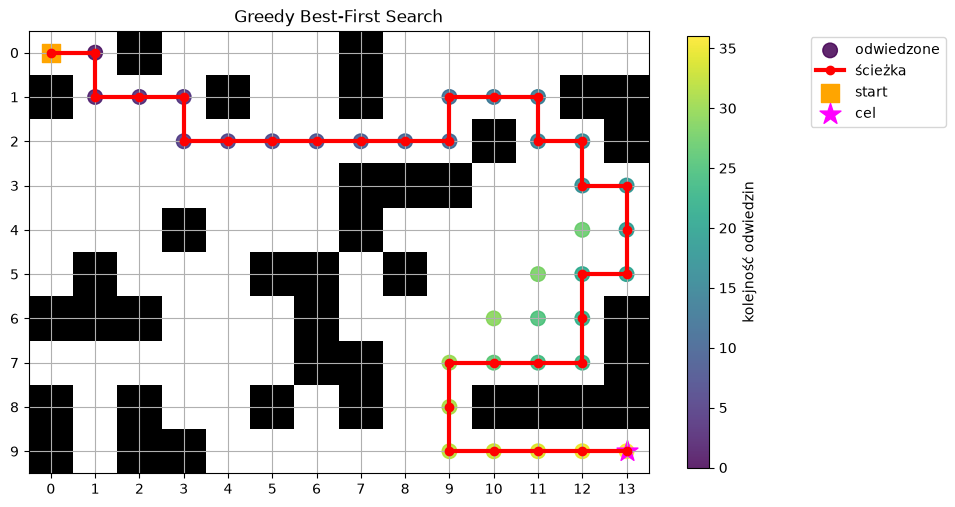

In [7]:
def greedy_best_first(start, goal):
    # W kopcu trzymamy (h, stan, rodzic) – rodzica zapisujemy przy zdjęciu z kopca,
    # tak jak w DFS.
    heap = []
    heapq.heappush(heap, (manhattan(start, goal), start, None))

    visited = set()
    parent = {}
    visit_order = []

    while heap:
        _, current, current_parent = heapq.heappop(heap)

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                heapq.heappush(
                    heap,
                    (manhattan(neighbor, goal), neighbor, current)
                )

    return None, visit_order


greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy - długość ścieżki:", len(greedy_path) - 1)
print("Greedy - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


A* - koszt: 22
A* - odwiedzone stany: 46
A* - ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


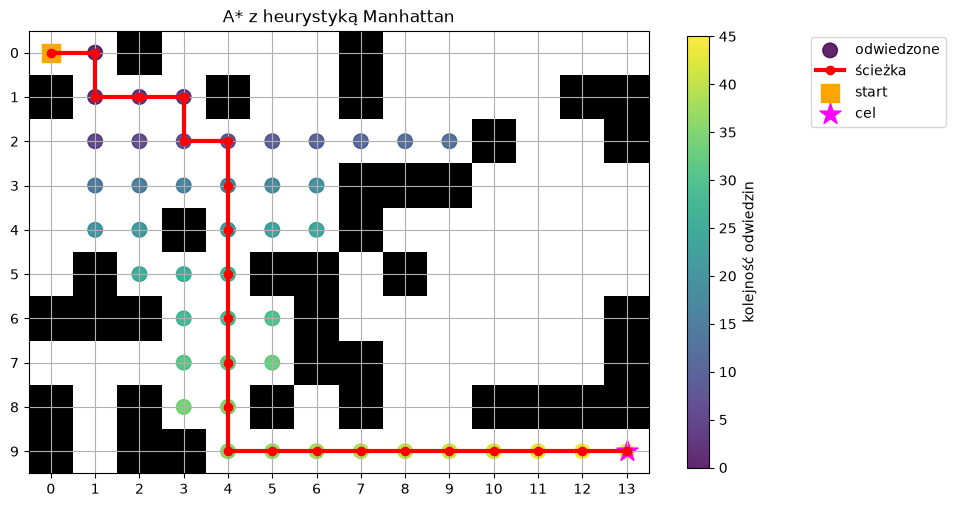

In [8]:
def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [9]:

results = [
    ("BFS", len(bfs_path) - 1, len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, len(greedy_visited)),
    ("A*", len(astar_path) - 1, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Długość ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 50)

for name, path_len, visited_count in results:
    print(f"{name:<12} {path_len:<18} {visited_count}")


Algorytm     Długość ścieżki    Odwiedzone stany
--------------------------------------------------
BFS          22                 103
DFS          42                 50
Greedy       32                 37
A*           22                 46



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [10]:

astar_euclidean_path, astar_euclidean_visited, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))


A* Manhattan - odwiedzone stany: 46
A* Euclidean - odwiedzone stany: 59



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


In [11]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))


A* z h=0 - odwiedzone stany: 103
BFS       - odwiedzone stany: 103



# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


Koszt: 30
Odwiedzone stany: 41


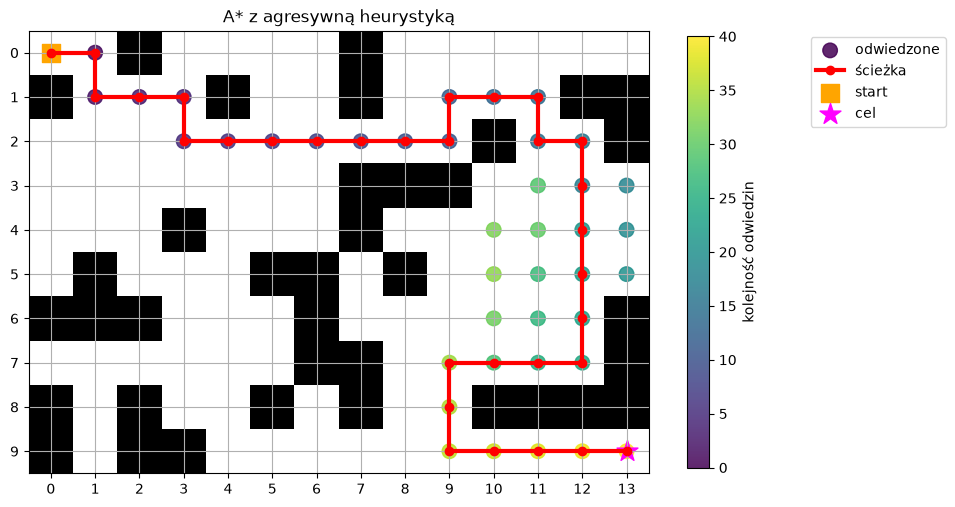

In [12]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)



# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

---

## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.

---

## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def my_heuristic(a, b):
    ...
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.

---

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?
2. Jaką heurystykę zastosować?
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

---

## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

---

## Zadanie 6 — pytanie koncepcyjne

Wyjaśnij własnymi słowami różnicę między:

$$
g(n)
$$

a

$$
h(n)
$$

w algorytmie A*.


## Zadanie 1 — zmiana kolejności ruchów w `get_neighbors()`

Kolejność ruchów wyciągam do zmiennej `MOVES`, żeby ją łatwo zmieniać, i sprawdzam DFS oraz BFS
dla kilku kolejności, a na końcu dla **wszystkich 24**.

góra, dół, lewo, prawo     DFS: ścieżka 42, odwiedzone  50   |   BFS: ścieżka 22, odwiedzone 103


prawo, lewo, dół, góra     DFS: ścieżka 56, odwiedzone  88   |   BFS: ścieżka 22, odwiedzone 102
prawo, dół, góra, lewo     DFS: ścieżka 58, odwiedzone  95   |   BFS: ścieżka 22, odwiedzone 102


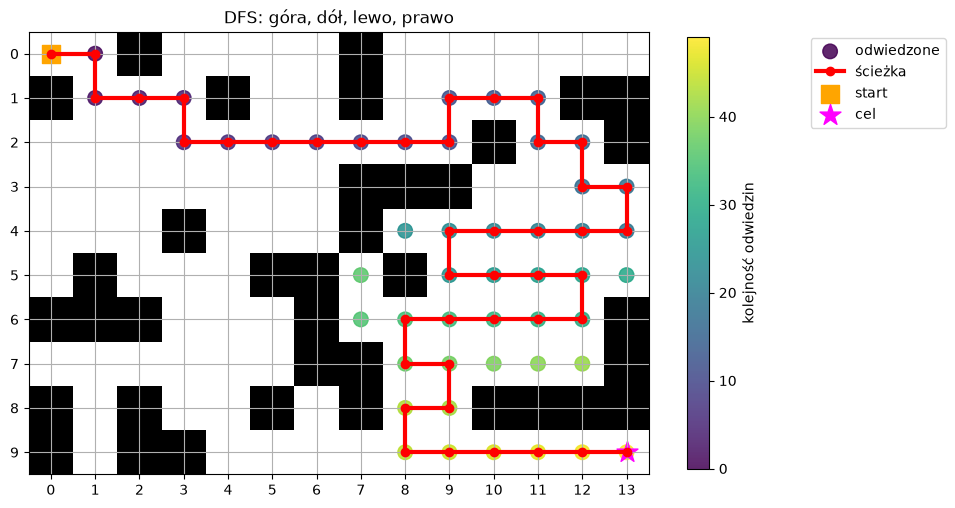

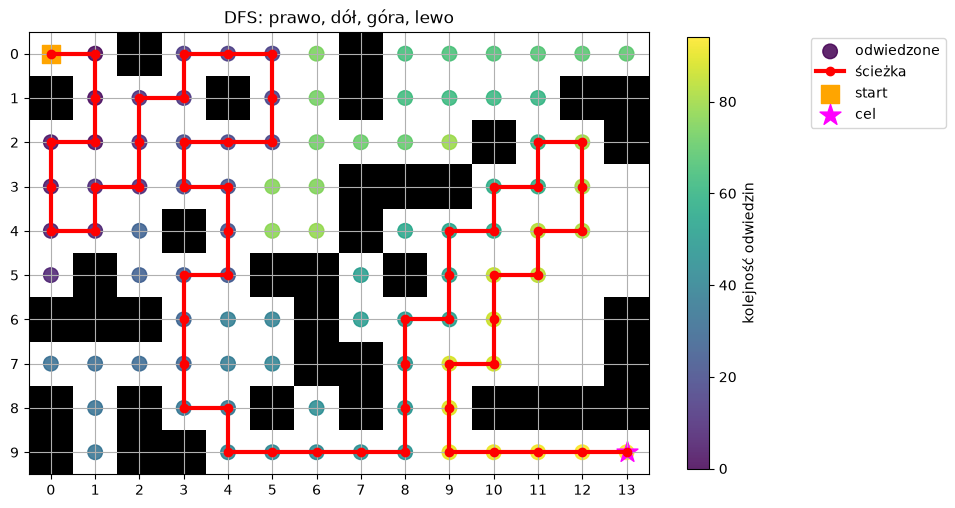


Wszystkie 24 kolejności ruchów:
DFS: długość ścieżki od 22 do 62 | odwiedzone od 23 do 103
BFS: długość ścieżki zawsze [22] | odwiedzone [102, 103]


In [13]:
# Zadanie 1 — zmiana kolejności ruchów w get_neighbors()
from itertools import permutations

# Kolejność ruchów trzymamy w zmiennej MOVES, żeby można ją było łatwo zmieniać.
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # góra, dół, lewo, prawo (jak w oryginale)


def get_neighbors(state):
    r, c = state
    neighbors = []
    for dr, dc in MOVES:  # <-- jedyna zmiana: kolejność bierzemy z MOVES
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == 0:
            neighbors.append((nr, nc))
    return neighbors


def porownaj_kolejnosc(kolejnosc, nazwa):
    global MOVES
    MOVES = kolejnosc
    p_dfs, v_dfs = dfs(start, goal)
    p_bfs, v_bfs = bfs(start, goal)
    print(f"{nazwa:<26} DFS: ścieżka {len(p_dfs) - 1:>2}, odwiedzone {len(v_dfs):>3}"
          f"   |   BFS: ścieżka {len(p_bfs) - 1}, odwiedzone {len(v_bfs)}")
    return p_dfs, v_dfs


ORYGINAL = [(-1, 0), (1, 0), (0, -1), (0, 1)]
dfs_p1, dfs_v1 = porownaj_kolejnosc(ORYGINAL, "góra, dół, lewo, prawo")
dfs_p2, dfs_v2 = porownaj_kolejnosc(list(reversed(ORYGINAL)), "prawo, lewo, dół, góra")
dfs_p3, dfs_v3 = porownaj_kolejnosc([(0, 1), (1, 0), (-1, 0), (0, -1)], "prawo, dół, góra, lewo")

draw_grid(dfs_p1, dfs_v1, "DFS: góra, dół, lewo, prawo")
draw_grid(dfs_p3, dfs_v3, "DFS: prawo, dół, góra, lewo")

# Wszystkie 24 kolejności ruchów naraz
wyniki_dfs, wyniki_bfs = [], []
for kolejnosc in permutations(ORYGINAL):
    MOVES = list(kolejnosc)
    p, v = dfs(start, goal)
    wyniki_dfs.append((len(p) - 1, len(v)))
    p, v = bfs(start, goal)
    wyniki_bfs.append((len(p) - 1, len(v)))

print()
print("Wszystkie 24 kolejności ruchów:")
print("DFS: długość ścieżki od", min(d for d, _ in wyniki_dfs), "do", max(d for d, _ in wyniki_dfs),
      "| odwiedzone od", min(v for _, v in wyniki_dfs), "do", max(v for _, v in wyniki_dfs))
print("BFS: długość ścieżki zawsze", sorted({d for d, _ in wyniki_bfs}),
      "| odwiedzone", sorted({v for _, v in wyniki_bfs}))

MOVES = ORYGINAL  # przywracamy oryginalną kolejność


**Wnioski (zadanie 1).**

- **DFS:** zmiana kolejności ruchów zmienia i ścieżkę, i liczbę odwiedzonych stanów (po 24 kolejnościach: ścieżki od 22 do 62 kroków, odwiedzone od 23 do 103). DFS wchodzi „w głąb" w pierwszym wybranym kierunku i nie ma gwarancji najkrótszej drogi.
- **BFS:** zawsze znajduje 22 kroki. Kolejność zmienia tylko to, którą z równie krótkich ścieżek wybierze (i o 1 liczbę odwiedzonych stanów), bo BFS przetwarza stany warstwami.

## Zadanie 2 — mapa, na której A\* wyraźnie wygrywa z BFS

Zmieniam planszę na pustą (bez ścian). Plansza oryginalna zostaje zapamiętana i przywrócona na końcu komórki.

Mapa A: pusta, start i cel w jednym wierszu  BFS odwiedzone: 115   A* odwiedzone:  14


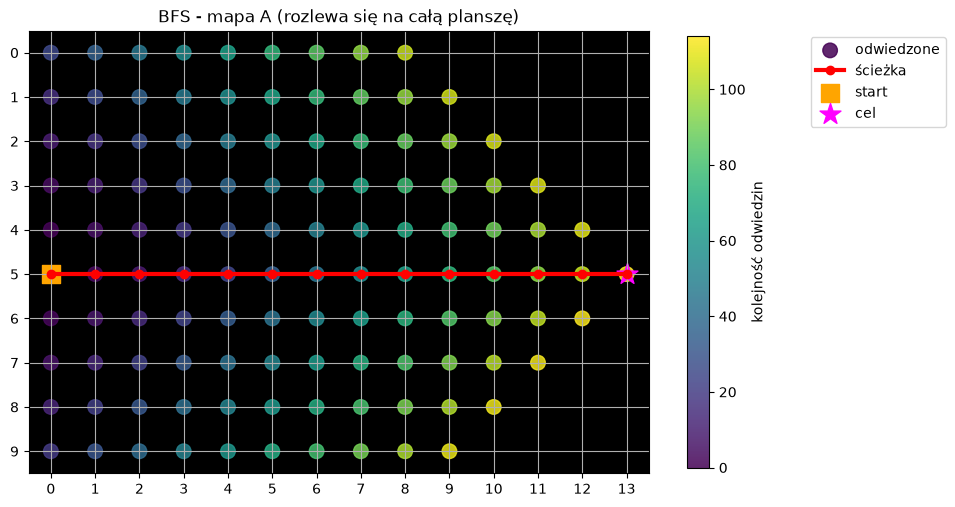

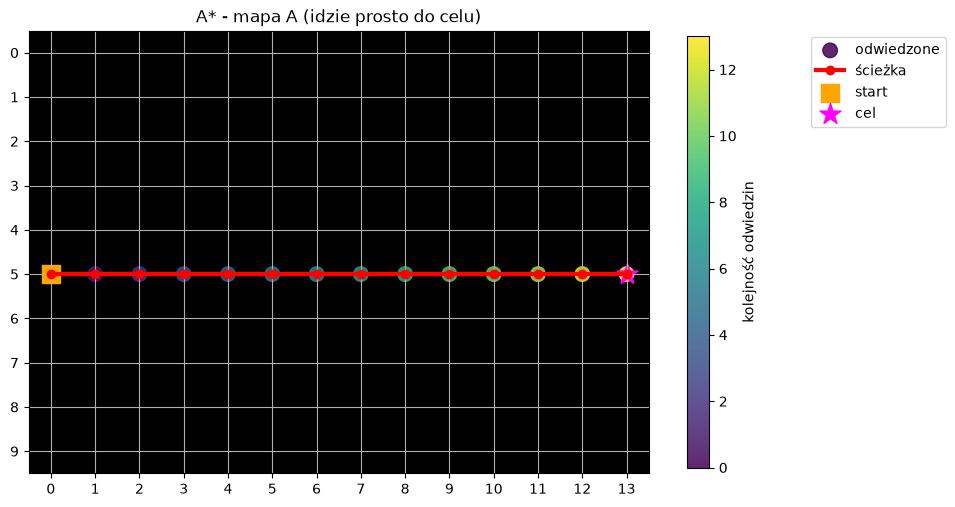

Mapa B: pusta, z rogu do rogu                BFS odwiedzone: 140   A* odwiedzone: 140
Mapa B, A* z lepszym rozstrzyganiem remisów  A* odwiedzone:  23
Przywrócono oryginalną planszę: 10 x 14 | start (0, 0) | cel (9, 13)


In [14]:
# Zadanie 2 — mapa, na której A* wyraźnie wygrywa z BFS
import itertools

# Zapamiętujemy oryginalną planszę, żeby na końcu ją przywrócić.
grid_oryg, start_oryg, goal_oryg = grid, start, goal


def ustaw_mape(nowa_grid, nowy_start, nowy_cel):
    global grid, rows, cols, start, goal
    grid, rows, cols = nowa_grid, len(nowa_grid), len(nowa_grid[0])
    start, goal = nowy_start, nowy_cel


def porownaj_bfs_astar(nazwa):
    p_b, v_b = bfs(start, goal)
    p_a, v_a, _ = astar(start, goal)
    print(f"{nazwa:<44} BFS odwiedzone: {len(v_b):>3}   A* odwiedzone: {len(v_a):>3}")
    return p_b, v_b, p_a, v_a


pusta = [[0] * 14 for _ in range(10)]  # plansza 10 x 14 bez żadnych ścian

# Mapa A: pusta plansza, start i cel w TYM SAMYM wierszu -> A* idzie prosto do celu
ustaw_mape(pusta, (5, 0), (5, 13))
pb, vb, pa, va = porownaj_bfs_astar("Mapa A: pusta, start i cel w jednym wierszu")
draw_grid(pb, vb, "BFS - mapa A (rozlewa się na całą planszę)")
draw_grid(pa, va, "A* - mapa A (idzie prosto do celu)")

# Mapa B: pusta plansza, z rogu do rogu. Wynik zaskakuje: A* nie pomaga.
ustaw_mape(pusta, (0, 0), (9, 13))
porownaj_bfs_astar("Mapa B: pusta, z rogu do rogu")


# Dlaczego? Na mapie B wszystkie pola mają f = 22 (remis), a kopiec rozstrzyga remis współrzędnymi
# stanu, a nie bliskością celu. Poprawka: klucz (f, h, licznik, stan) - przy równym f weź stan
# BLIŻSZY celu (mniejsze h), a przy dalszym remisie kolejność dodania.
def astar_remisy(start, goal, heuristic=manhattan):
    licznik = itertools.count()
    h0 = heuristic(start, goal)
    open_heap = [(h0, h0, next(licznik), start)]
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, _, _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue

            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g
                h = heuristic(neighbor, goal)
                heapq.heappush(open_heap, (tentative_g + h, h, next(licznik), neighbor))

    return None, visit_order, float("inf")


p_r, v_r, _ = astar_remisy(start, goal)
print(f"{'Mapa B, A* z lepszym rozstrzyganiem remisów':<44} A* odwiedzone: {len(v_r):>3}")

# Przywracamy oryginalną planszę
ustaw_mape(grid_oryg, start_oryg, goal_oryg)
print("Przywrócono oryginalną planszę:", rows, "x", cols, "| start", start, "| cel", goal)


**Wnioski (zadanie 2).**

- **Mapa A** (pusta, start i cel w jednym wierszu): BFS odwiedza 115 stanów, A\* tylko 14. A\* ma f = 13 wyłącznie dla pól w tym wierszu, a każde pole obok ma f ≥ 15, więc nigdy nie jest rozwijane.
- **Mapa B** (pusta, z rogu do rogu): A\* odwiedza tyle samo stanów co BFS (140). Wszystkie pola mają f = 22, a remis rozstrzygają współrzędne, nie bliskość celu. Dopiero klucz `(f, h, licznik, stan)` sprawia, że A\* idzie do celu (wynik: 23 odwiedzone stany zamiast 140).
- Wniosek: A\* pomaga tylko wtedy, gdy heurystyka naprawdę odróżnia dobre pola od złych.

## Zadanie 3 — własna heurystyka

Moja heurystyka to **odległość Czebyszewa**: $h(n)=\max(|\Delta r|,|\Delta c|)$.
Dopuszczalność sprawdzam doświadczalnie: liczę prawdziwy koszt $h^*(n)$ dla każdego pola (BFS od celu wstecz)
i porównuję z $h(n)$.

In [15]:
# Zadanie 3 — własna heurystyka
def my_heuristic(a, b):
    # odległość Czebyszewa: większa z różnic wierszy i kolumn
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))


def h_star_dla_wszystkich(goal):
    # Prawdziwy koszt dojścia do celu h*(n) dla KAŻDEGO pola: BFS "od celu wstecz".
    # Ruchy są odwracalne, a koszty równe, więc odległość od celu = h*(n).
    dist = {goal: 0}
    q = deque([goal])
    while q:
        cur = q.popleft()
        for nb in get_neighbors(cur):
            if nb not in dist:
                dist[nb] = dist[cur] + 1
                q.append(nb)
    return dist


h_star = h_star_dla_wszystkich(goal)


def czy_dopuszczalna(h):
    # h jest dopuszczalna, jeśli dla każdego pola h(n) <= h*(n)
    return all(h(n, goal) <= h_star[n] + 1e-9 for n in h_star)


heurystyki = {
    "h = 0": lambda a, b: 0,
    "Czebyszew (moja)": my_heuristic,
    "Euklides": euclidean,
    "Manhattan": manhattan,
    "3 * Manhattan": lambda a, b: 3 * manhattan(a, b),
}

print(f"{'heurystyka':<18} {'dopuszczalna?':<15} {'odwiedzone':<11} {'koszt drogi'}")
print("-" * 58)
for nazwa, h in heurystyki.items():
    p, v, koszt = astar(start, goal, heuristic=h)
    print(f"{nazwa:<18} {'tak' if czy_dopuszczalna(h) else 'NIE':<15} {len(v):<11} {koszt}")


heurystyka         dopuszczalna?   odwiedzone  koszt drogi
----------------------------------------------------------
h = 0              tak             103         22
Czebyszew (moja)   tak             69          22
Euklides           tak             59          22
Manhattan          tak             46          22
3 * Manhattan      NIE             41          30


**Wnioski (zadanie 3).**

- Czebyszew jest **dopuszczalny**: przy ruchach góra/dół/lewo/prawo droga ma co najmniej $|\Delta r|+|\Delta c|$ kroków, a Czebyszew bierze tylko większą z tych liczb, więc zawsze jest $\le$ Manhattan $\le h^*$.
- Kolejność siły (im więcej wiedzy bez przeszacowania, tym mniej odwiedzonych stanów): $h=0$ (103) $<$ Czebyszew (69) $<$ Euklides (59) $<$ Manhattan (46).
- $3\cdot$Manhattan **nie jest dopuszczalna**: A\* odwiedza mniej stanów, ale droga jest dłuższa niż optymalna (30 zamiast 22).

## Zadanie 4 — ruch po przekątnej

Dodaję 8 kierunków ruchu. Skos nie może „przecinać rogu" ściany. Testuję dwa koszty skosu: 1 oraz $\sqrt{2}$,
a dopuszczalność każdej heurystyki sprawdzam doświadczalnie (prawdziwe koszty $h^*$ liczę Dijkstrą od celu).


Koszt ruchu po przekątnej = 1.00
heurystyka   dopuszczalna?   odwiedzone  koszt drogi
Manhattan    NIE             27          20.00
Euklides     NIE             58          20.00
Czebyszew    tak             81          20.00
oktylna      NIE             54          20.00

Koszt ruchu po przekątnej = 1.41
heurystyka   dopuszczalna?   odwiedzone  koszt drogi
Manhattan    NIE             27          20.83
Euklides     tak             59          20.83
Czebyszew    tak             68          20.83
oktylna      tak             57          20.83


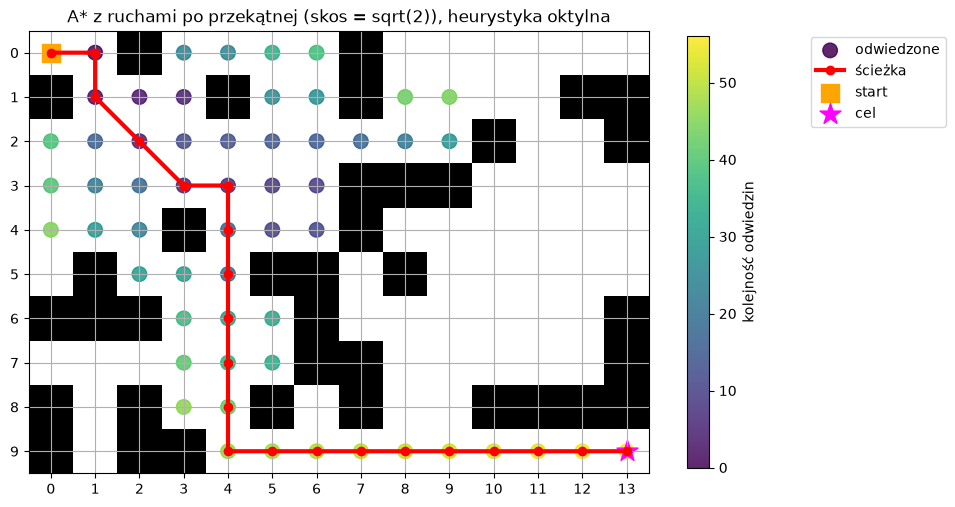

In [16]:
# Zadanie 4 — ruch po przekątnej
RUCHY_8 = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]


def sasiedzi_8(state, koszt_skosu):
    # Zwraca listę (sąsiad, koszt wejścia). Ruch po skosie kosztuje `koszt_skosu`, prosty 1.
    r, c = state
    wynik = []
    for dr, dc in RUCHY_8:
        nr, nc = r + dr, c + dc
        if not (0 <= nr < rows and 0 <= nc < cols) or grid[nr][nc] == 1:
            continue
        skos = dr != 0 and dc != 0
        # Nie wolno "przecinać rogu": skos jest zabroniony, gdy któreś pole obok to ściana.
        if skos and (grid[r + dr][c] == 1 or grid[r][c + dc] == 1):
            continue
        wynik.append(((nr, nc), koszt_skosu if skos else 1.0))
    return wynik


def astar_8(start, goal, heuristic, koszt_skosu):
    open_heap = [(heuristic(start, goal), start)]
    g_score = {start: 0.0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor, koszt in sasiedzi_8(current, koszt_skosu):
            if neighbor in closed:
                continue

            tentative_g = g_score[current] + koszt  # g rośnie o 1 albo o koszt skosu
            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g
                heapq.heappush(open_heap, (tentative_g + heuristic(neighbor, goal), neighbor))

    return None, visit_order, float("inf")


def czebyszew(a, b):
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))


def oktylna(a, b):
    # dokładny koszt na pustej planszy, gdy skos kosztuje sqrt(2)
    dr, dc = abs(a[0] - b[0]), abs(a[1] - b[1])
    return (dr + dc) + (math.sqrt(2) - 2) * min(dr, dc)


def h_star_8(goal, koszt_skosu):
    # Prawdziwy koszt dojścia do celu z każdego pola (Dijkstra od celu; ruchy są symetryczne).
    dist = {goal: 0.0}
    kopiec = [(0.0, goal)]
    while kopiec:
        d, cur = heapq.heappop(kopiec)
        if d > dist[cur]:
            continue
        for nb, koszt in sasiedzi_8(cur, koszt_skosu):
            nd = d + koszt
            if nd < dist.get(nb, float("inf")):
                dist[nb] = nd
                heapq.heappush(kopiec, (nd, nb))
    return dist


heurystyki_8 = {
    "Manhattan": manhattan,
    "Euklides": euclidean,
    "Czebyszew": czebyszew,
    "oktylna": oktylna,
}

for koszt_skosu in (1.0, math.sqrt(2)):
    h_star8 = h_star_8(goal, koszt_skosu)
    print(f"\nKoszt ruchu po przekątnej = {koszt_skosu:.2f}")
    print(f"{'heurystyka':<12} {'dopuszczalna?':<15} {'odwiedzone':<11} {'koszt drogi'}")
    for nazwa, h in heurystyki_8.items():
        dopuszczalna = all(h(n, goal) <= h_star8[n] + 1e-9 for n in h_star8)
        p, v, koszt = astar_8(start, goal, h, koszt_skosu)
        print(f"{nazwa:<12} {'tak' if dopuszczalna else 'NIE':<15} {len(v):<11} {koszt:.2f}")

p8, v8, k8 = astar_8(start, goal, oktylna, math.sqrt(2))
draw_grid(p8, v8, "A* z ruchami po przekątnej (skos = sqrt(2)), heurystyka oktylna")


**Odpowiedzi (zadanie 4).**

1. **Czy Manhattan nadal jest najlepszym wyborem?** Nie. Ruch po skosie zmienia wiersz i kolumnę naraz, więc dojście może kosztować mniej niż $|\Delta r|+|\Delta c|$. Manhattan przeszacowuje, przestaje być dopuszczalny (tabela wyżej: NIE) i A\* może zwrócić drogę nieoptymalną. Na tej konkretnej mapie Manhattan akurat znalazł optymalny koszt (20,83), ale to szczęście, a nie gwarancja.
2. **Jaką heurystykę zastosować?** Gdy skos kosztuje 1: Czebyszewa. Gdy kosztuje $\sqrt{2}$: oktylną $h=(d_r+d_c)+(\sqrt{2}-2)\min(d_r,d_c)$, bo jest dokładna na pustej planszy. Euklides jest dopuszczalny tylko przy koszcie $\sqrt{2}$.
3. **Co zmieni koszt skosu $\sqrt{2}$?** Koszty przestają być całkowite, więc liczba kroków $\ne$ koszt: BFS nie gwarantuje już najtańszej drogi, a $g$ w A\* rośnie o 1 albo $\sqrt{2}$. Skos ($\approx 1{,}41$) jest tańszy niż dwa ruchy proste (2), ale droższy niż jeden prosty (1).

## Zadanie 5 — teren o różnych kosztach

Koszt **wejścia** na pole: zwykłe pole = 1, piasek = 3, bagno = 5.

Pomysł: BFS liczy **kroki**, a nie **koszt**. Postawimy bagno w miejscu, przez które prowadzi
każda najkrótsza (22-krokowa) droga, i zobaczymy, czy BFS nadal znajdzie najtańszą trasę.

Algorytm Kroki   Koszt
------------------------
BFS      22      52
A*       28      28


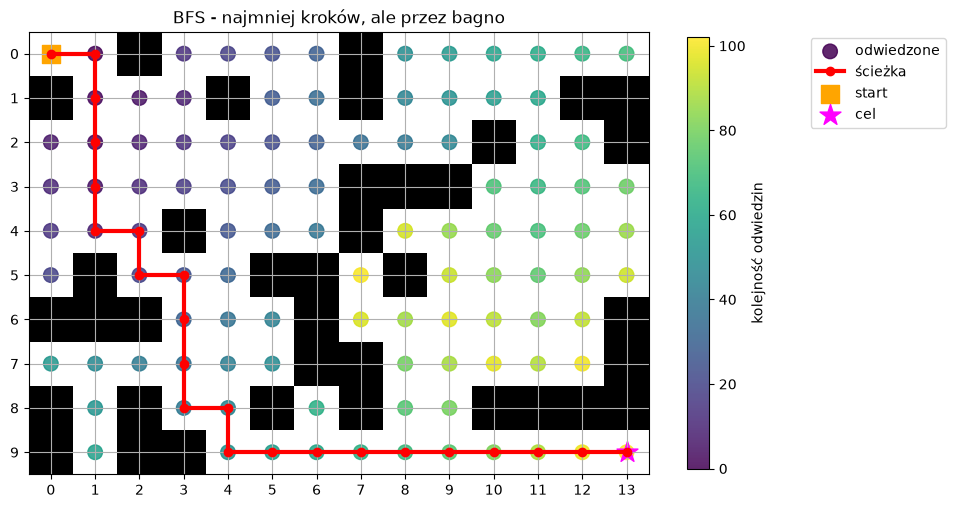

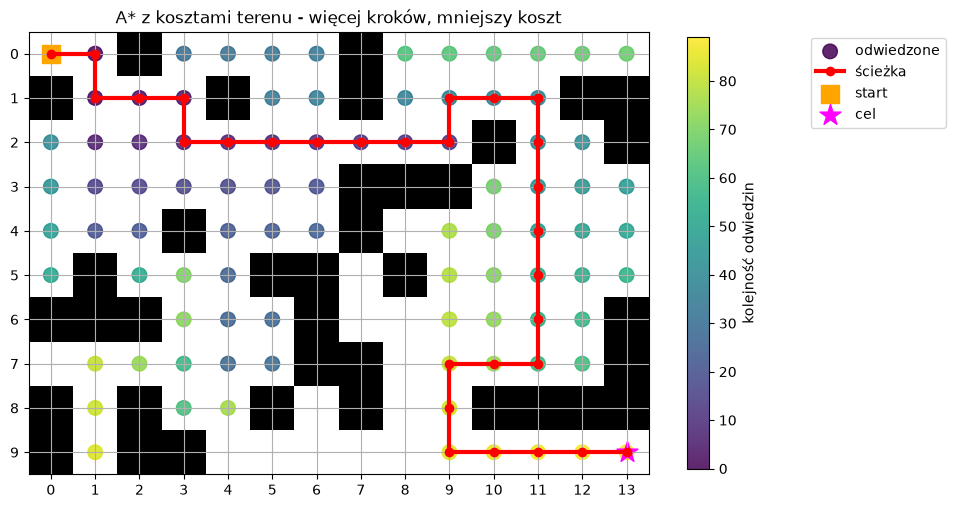

In [17]:
# Zadanie 5 — teren o różnych kosztach wejścia
# zwykłe pole = 1, piasek = 3, bagno = 5. Pola spoza słownika `teren` kosztują 1.

BAGNO = 5
PIASEK = 3

teren = {}
# Bagno leży w "wąskim gardle" mapy: każda najkrótsza (22-krokowa) droga musi przejść
# (8,4) -> (9,4) i dalej dolnym rzędem do celu.
for pole in [(8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8)]:
    teren[pole] = BAGNO
# Piasek na lewej części najkrótszej ścieżki.
for pole in [(5, 2), (5, 3), (6, 3)]:
    teren[pole] = PIASEK


def koszt_wejscia(pole):
    return teren.get(pole, 1)  # domyślnie 1


def koszt_sciezki(sciezka):
    # Start nic nie kosztuje (nie "wchodzimy" na niego) - liczymy wejścia na kolejne pola.
    return sum(koszt_wejscia(p) for p in sciezka[1:])


def astar_teren(start, goal, heuristic=manhattan):
    # Identyczny jak astar(), z JEDNĄ zmianą: g rośnie o koszt wejścia na pole, a nie zawsze o 1.
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue

            tentative_g = g_score[current] + koszt_wejscia(neighbor)  # <-- jedyna zmiana

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g
                heapq.heappush(open_heap, (tentative_g + heuristic(neighbor, goal), neighbor))

    return None, visit_order, float("inf")


astar_t_path, astar_t_visited, astar_t_cost = astar_teren(start, goal)

print(f"{'Algorytm':<8} {'Kroki':<7} {'Koszt'}")
print("-" * 24)
print(f"{'BFS':<8} {len(bfs_path) - 1:<7} {koszt_sciezki(bfs_path)}")
print(f"{'A*':<8} {len(astar_t_path) - 1:<7} {koszt_sciezki(astar_t_path)}")

draw_grid(bfs_path, bfs_visited, "BFS - najmniej kroków, ale przez bagno")
draw_grid(astar_t_path, astar_t_visited, "A* z kosztami terenu - więcej kroków, mniejszy koszt")


### Odpowiedź na pytanie z zadania 5

**Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki? Nie.**

BFS minimalizuje **liczbę kroków**, a nie **sumę kosztów**. Dopóki każdy krok kosztuje tyle samo,
najmniej kroków oznacza najmniejszy koszt i dlatego BFS działa. Gdy koszty pól są różne, ta równość znika:
droga z najmniejszą liczbą kroków może prowadzić przez drogie pola.

**Dowód na naszej mapie:**
- BFS: 22 kroki, ale koszt **52** (wchodzi w bagno).
- A* z kosztami terenu: 28 kroków, ale koszt **28** (objeżdża bagno górą).

Droga A* jest dłuższa o 6 kroków i tańsza o 24.

**Co zmieniłem w A*:** jedną linijkę. Zamiast `g + 1` jest `g + koszt_wejscia(neighbor)`,
czyli `g(n)` to teraz suma rzeczywistych kosztów, a nie liczba kroków.

**Czy Manhattan nadal jest dopuszczalny?** Tak. Najtańsze pole kosztuje 1, więc dojście do celu nie może
kosztować mniej niż liczba kroków, którą szacuje Manhattan: `h(n) <= h*(n)`. Heurystyka jest też spójna,
więc A* ze zbiorem `closed` nadal zwraca drogę optymalną. (Gdyby jakiś teren kosztował mniej niż 1,
Manhattan przestałby być dopuszczalny.)

## Zadanie 6 — $g(n)$ a $h(n)$

- **$g(n)$** to **rzeczywisty, już poniesiony** koszt drogi od startu do stanu $n$. Znamy go dokładnie, bo liczymy go po drodze.
- **$h(n)$** to **oszacowanie** kosztu, który jeszcze zostało od $n$ do celu. To tylko domysł (np. Manhattan, który nie widzi ścian).
- A\* wybiera stan o najmniejszym $f(n)=g(n)+h(n)$, czyli łączy „ile już zapłaciłem" z „ile jeszcze prawdopodobnie zapłacę".

# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [18]:
# 8-puzzle: A* z heurystyką = suma odległości Manhattan każdego kafelka od jego pozycji docelowej

start_puzzle = (
    0, 2, 4,
    3, 6, 5,
    7, 1, 8
)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

# Gdzie powinien stać każdy kafelek: kafelek -> (wiersz, kolumna)
POZYCJA_CELU = {kafel: divmod(i, 3) for i, kafel in enumerate(goal_puzzle)}


def puzzle_neighbors(stan):
    # 0 = puste pole. Zamieniamy je z sąsiednim kafelkiem. Tworzymy NOWĄ krotkę
    # (krotki są niemodyfikowalne i hashowalne, więc nadają się do zbioru `closed`).
    i = stan.index(0)
    r, c = divmod(i, 3)
    wynik = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < 3 and 0 <= nc < 3:
            j = nr * 3 + nc
            nowy = list(stan)
            nowy[i], nowy[j] = nowy[j], nowy[i]
            wynik.append(tuple(nowy))
    return wynik


def puzzle_manhattan(stan):
    # Suma odległości Manhattan kafelków od ich pozycji docelowych (pustego pola nie liczymy).
    suma = 0
    for i, kafel in enumerate(stan):
        if kafel != 0:
            r, c = divmod(i, 3)
            gr, gc = POZYCJA_CELU[kafel]
            suma += abs(r - gr) + abs(c - gc)
    return suma


def czy_rozwiazywalne(stan):
    # Dla planszy 3x3 układanka jest rozwiązywalna, gdy liczba inwersji (par kafelków w złej
    # kolejności, bez pustego pola) jest parzysta.
    kafle = [k for k in stan if k != 0]
    inwersje = sum(1 for a in range(len(kafle)) for b in range(a + 1, len(kafle)) if kafle[a] > kafle[b])
    return inwersje % 2 == 0


def astar_puzzle(start, goal, heuristic):
    open_heap = [(heuristic(start), start)]
    g_score = {start: 0}
    parent = {start: None}
    closed = set()

    while open_heap:
        _, stan = heapq.heappop(open_heap)

        if stan in closed:
            continue

        closed.add(stan)

        if stan == goal:
            return reconstruct_path(parent, goal), len(closed)

        for nowy in puzzle_neighbors(stan):
            if nowy in closed:
                continue

            tentative_g = g_score[stan] + 1
            if tentative_g < g_score.get(nowy, float("inf")):
                g_score[nowy] = tentative_g
                parent[nowy] = stan
                heapq.heappush(open_heap, (tentative_g + heuristic(nowy), nowy))

    return None, len(closed)


def pokaz_plansze(stan):
    for w in range(3):
        print(" ".join("_" if k == 0 else str(k) for k in stan[3 * w:3 * w + 3]))


print("Czy start jest rozwiązywalny?", czy_rozwiazywalne(start_puzzle))

sciezka_puzzle, rozwiniete_astar = astar_puzzle(start_puzzle, goal_puzzle, puzzle_manhattan)
print("A* (suma Manhattan): ruchów:", len(sciezka_puzzle) - 1, "| rozwinięte stany:", rozwiniete_astar)

_, rozwiniete_h0 = astar_puzzle(start_puzzle, goal_puzzle, lambda stan: 0)
print("A* z h = 0 (jak BFS): rozwinięte stany:", rozwiniete_h0)

# Ruchy pustego pola w kolejnych krokach
nazwy_ruchow = {(-1, 0): "góra", (1, 0): "dół", (0, -1): "lewo", (0, 1): "prawo"}
ruchy = []
for a, b in zip(sciezka_puzzle, sciezka_puzzle[1:]):
    ia, ib = a.index(0), b.index(0)
    ruchy.append(nazwy_ruchow[(ib // 3 - ia // 3, ib % 3 - ia % 3)])
print("Ruchy pustego pola:", ", ".join(ruchy))

print("\nStart:")
pokaz_plansze(start_puzzle)
print("\nCel:")
pokaz_plansze(goal_puzzle)


Czy start jest rozwiązywalny? True
A* (suma Manhattan): ruchów: 20 | rozwinięte stany: 385
A* z h = 0 (jak BFS): rozwinięte stany: 41210
Ruchy pustego pola: prawo, prawo, dół, lewo, lewo, góra, prawo, dół, dół, prawo, góra, góra, lewo, dół, lewo, góra, prawo, dół, prawo, dół

Start:
_ 2 4
3 6 5
7 1 8

Cel:
1 2 3
4 5 6
7 8 _


**Komentarz (8-puzzle).** Stan to krotka 9 liczb (0 = puste pole), a akcja to zamiana pustego pola z sąsiednim kafelkiem. Suma odległości Manhattan jest **dopuszczalna**, bo każdy ruch przesuwa dokładnie jeden kafelek o jedno pole, więc do ułożenia potrzeba co najmniej tylu ruchów, ile wynosi ta suma. Jest też **spójna**, bo jeden ruch zmienia sumę o co najwyżej 1, więc A\* ze zbiorem `closed` zwraca rozwiązanie optymalne. Porównanie z $h=0$ pokazuje, ile stanów oszczędza heurystyka.

# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne

1. Co jest stanem w problemie wyszukiwania drogi?
2. Czym różni się BFS od DFS?
3. Dlaczego BFS może potrzebować dużo pamięci?
4. Co oznacza $g(n)$?
5. Co oznacza $h(n)$?
6. Co oznacza $f(n)$?
7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
8. Co oznacza, że heurystyka jest dopuszczalna?
9. Co się stanie w A*, gdy $h(n)=0$?
10. Czy A* zawsze jest szybszy od BFS?


## Odpowiedzi na wszystkie pytania z notatnika

*(Sekcja 13, czyli 8-puzzle, to zadanie programistyczne, nie pytanie — pominięte tutaj.)*

### Pytania z sekcji 3 (BFS)

**Pytanie 1. Dlaczego BFS używa kolejki, a nie stosu?**

**Odp:** Bo kolejka (FIFO) wyjmuje najstarszy stan, czyli najbliższy startowi.

**Dlaczego:** Dzięki temu BFS rozwija stany warstwami: najpierw te oddalone o 1 krok, potem o 2 itd. Stos (LIFO) wyjmuje najnowszy, czyli najgłębszy stan, a to już jest DFS.

**Pytanie 2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?**

**Odp:** Bo do każdego stanu dociera najmniejszą możliwą liczbą kroków.

**Dlaczego:** Wszystkie stany z warstwy k są rozwijane przed jakimkolwiek stanem z warstwy k+1, więc gdy cel pojawia się pierwszy raz, jest osiągnięty minimalną liczbą kroków. Przy równych kosztach koszt = liczba kroków × stała, więc najmniej kroków oznacza najmniejszy koszt.

**Pytanie 3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?**

**Odp:** Pamięć gwałtownie rośnie i może się skończyć.

**Dlaczego:** BFS trzyma w kolejce całą warstwę granicy oraz zbiór wszystkich odwiedzonych stanów. Liczba stanów w warstwie rośnie wykładniczo z głębokością (ok. $b^d$). Dla bardzo dużych przestrzeni (np. szachy) BFS się nie zmieści w pamięci.

### Zadania z sekcji 12

**Pytanie 4 (zad. 1). Czy po zmianie kolejności ruchów w `get_neighbors()` DFS znajdzie inną ścieżkę i czy zmieni się liczba odwiedzonych stanów? A BFS?**

**Odp:** Tak, DFS znajdzie inną ścieżkę i zmieni się liczba odwiedzonych stanów. Sprawdziłem wszystkie 24 kolejności ruchów: DFS dawał ścieżki od 22 do 62 kroków (18 różnych ścieżek) i odwiedzał od 23 do 103 stanów. BFS zawsze znajdował 22 kroki (odwiedzone 102–103, tylko 2 różne ścieżki).

**Dlaczego:** DFS wkłada sąsiadów na stos i bierze ostatnio dodanego, więc kolejność ruchów decyduje, w którą stronę wejdzie „w głąb"; może długo błądzić i nie ma gwarancji najkrótszej drogi. BFS rozwija warstwami, więc zawsze znajdzie najkrótszą (22). Kolejność ruchów zmienia tylko to, którą z równie krótkich ścieżek wybierze.

**Pytanie 5 (zad. 2). Jaka mapa sprawia, że BFS odwiedza dużo stanów, a A\* wyraźnie mniej? (i co dzieje się na mapie bez ścian?)**

**Odp:** Np. pusta plansza 10×14, start (5,0), cel (5,13) (ten sam wiersz, bez ścian). BFS odwiedza 115 stanów, A\* tylko 14.

**Dlaczego:** BFS rozlewa się we wszystkie strony, aż dojdzie do kolumny 13. A\* z Manhattanem ma f = 13 tylko dla pól w tym wierszu, a każde pole obok ma f ≥ 15, więc nigdy nie jest rozwijane. Zaskoczenie: na pustej planszy z rogu do rogu, (0,0) → (9,13), A\* odwiedził 140 stanów, czyli tyle samo co BFS. Wszystkie pola mają wtedy f = 22 (remis), a remis rozstrzygają współrzędne, nie bliskość celu.

**Pytanie 6 (zad. 3). Własna heurystyka: czy jest dopuszczalna i jak wypada na tle Manhattan, Euklidesa i h=0?**

**Odp:** Heurystyka Czebyszewa $h(n)=\max(|\Delta r|,|\Delta c|)$ jest dopuszczalna, ale słabsza od Manhattana. Odwiedzone stany (koszt zawsze 22): Manhattan 46, Euklides 59, Czebyszew 69, h=0 103.

**Dlaczego:** Przy ruchach góra/dół/lewo/prawo droga ma co najmniej $|\Delta r|+|\Delta c|$ kroków, a Czebyszew bierze tylko większą z tych liczb, więc zawsze jest ≤ Manhattan ≤ rzeczywisty koszt, czyli nie przeszacowuje. Im bliżej prawdziwego kosztu (ale nie powyżej), tym mniej stanów odwiedza A\*: $0 \le$ Czebyszew $\le$ Euklides $\le$ Manhattan $\le h^*$.

**Pytanie 7 (zad. 4). Czy po dodaniu ruchów po przekątnej Manhattan nadal jest najlepszym wyborem?**

**Odp:** Nie.

**Dlaczego:** Ruch po przekątnej zmienia wiersz i kolumnę naraz, więc dojście może kosztować mniej niż $|\Delta r|+|\Delta c|$. Np. z (0,0) do (9,13) na pustej planszy Manhattan = 22, a droga z przekątnymi ma 13 kroków. Manhattan przeszacowuje, więc przestaje być dopuszczalny i A\* może zwrócić drogę nieoptymalną.

**Pytanie 8 (zad. 4). Jaką heurystykę zastosować przy ruchach po przekątnej?**

**Odp:** Gdy ruch po przekątnej kosztuje 1: odległość Czebyszewa $\max(|\Delta r|,|\Delta c|)$. Gdy kosztuje $\sqrt{2}$: odległość oktylna $h=(d_r+d_c)+(\sqrt{2}-2)\cdot\min(d_r,d_c)$, gdzie $d_r=|\Delta r|$, $d_c=|\Delta c|$.

**Dlaczego:** To dokładny koszt dojścia na pustej planszy dla danego zestawu ruchów, więc jest dopuszczalna i najsilniejsza z możliwych. Euklides jest dopuszczalny tylko przy koszcie skosu $\sqrt{2}$ (wtedy jest słabszy od oktylnej). Przy koszcie 1 przeszacowuje (np. $d_r=d_c=9$: 12,7 wobec prawdziwych 9), więc się nie nadaje.

**Pytanie 9 (zad. 4). Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?**

**Odp:** Koszty przestają być całkowite, więc liczba kroków ≠ koszt. BFS przestaje gwarantować najtańszą drogę, potrzebny jest A\*/Dijkstra, w którym $g$ rośnie o 1 albo $\sqrt{2}$ (liczby zmiennoprzecinkowe).

**Dlaczego:** Ruch ukośny pokonuje $\sqrt{2}\approx 1{,}41$, więc jest tańszy niż dwa ruchy proste (2), ale droższy niż jeden prosty (1). „Najmniej kroków" nie oznacza już „najmniej kosztu", tak jak w zadaniu 5. Najlepsza heurystyka to oktylna; Manhattan dalej przeszacowuje (dla $d_r=d_c=9$: 18 wobec 12,7), Czebyszew jest dopuszczalny, ale słaby (9).

**Pytanie 10 (zad. 5). Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki, gdy pola mają różne koszty (1 / piasek 3 / bagno 5)?**

**Odp:** Nie.

**Dlaczego:** BFS minimalizuje liczbę kroków, a nie sumę kosztów. Gwarancja działa tylko wtedy, gdy każdy krok kosztuje tyle samo. W naszym eksperymencie BFS: 22 kroki, koszt 52 (wchodzi w bagno), a A\* z kosztami: 28 kroków, koszt 28. Szczegóły i kod: zadanie 5 wyżej.

**Pytanie 11 (zad. 6). Czym różni się $g(n)$ od $h(n)$ w algorytmie A\*?**

**Odp:** $g(n)$ to rzeczywisty, już poniesiony koszt drogi od startu do $n$; $h(n)$ to oszacowanie kosztu, który jeszcze zostało od $n$ do celu.

**Dlaczego:** $g$ znamy dokładnie, bo policzyliśmy je po drodze. $h$ to tylko domysł (np. Manhattan, który nie widzi ścian). A\* wybiera stan o najmniejszym $f=g+h$, czyli łączy „ile już zapłaciłem" z „ile jeszcze prawdopodobnie zapłacę".

### Pytania kontrolne z sekcji 15

**Pytanie 12. Co jest stanem w problemie wyszukiwania drogi?**

**Odp:** Para (wiersz, kolumna), czyli pozycja na planszy.

**Dlaczego:** Stan to cała informacja potrzebna do dalszego szukania. Tu wystarczy wiedzieć, na którym polu jesteśmy, bo ściany i cel się nie zmieniają. W 8-puzzle stanem byłoby całe ułożenie kafelków.

**Pytanie 13. Czym różni się BFS od DFS?**

**Odp:** BFS: kolejka FIFO, szuka wszerz, daje najkrótszą ścieżkę (przy równych kosztach), zużywa dużo pamięci. DFS: stos LIFO, idzie w głąb, nie gwarantuje najkrótszej ścieżki, zużywa mało pamięci (w wersji bez zbioru odwiedzonych).

**Dlaczego:** Różnią się tylko regułą wyjmowania z frontiera: BFS bierze najwcześniej dodany stan, DFS najpóźniej dodany.

**Pytanie 14. Dlaczego BFS może potrzebować dużo pamięci?**

**Odp:** Bo trzyma całą granicę poszukiwań.

**Dlaczego:** W kolejce jest cała bieżąca warstwa, a w `visited` wszystkie odwiedzone stany. Warstwa rośnie wykładniczo z głębokością ($b^d$), a DFS bez zbioru odwiedzonych pamięta tylko jedną gałąź (ok. $b\cdot d$).

**Pytanie 15. Co oznacza $g(n)$?**

**Odp:** Rzeczywisty koszt drogi od stanu początkowego do stanu $n$.

**Dlaczego:** Jest znany dokładnie, bo liczymy go po drodze, krok po kroku (w naszej mapie: liczba kroków).

**Pytanie 16. Co oznacza $h(n)$?**

**Odp:** Oszacowany koszt dojścia ze stanu $n$ do celu.

**Dlaczego:** To szybka ocena bez rozwiązywania problemu (np. Manhattan). Nie musi być dokładna, ma tylko kierować szukanie.

**Pytanie 17. Co oznacza $f(n)$?**

**Odp:** $f(n)=g(n)+h(n)$, czyli oszacowany całkowity koszt drogi od startu do celu przechodzącej przez $n$.

**Dlaczego:** A\* rozwija stan o najmniejszym $f$: łączy „tanio do tej pory" z „wygląda obiecująco".

**Pytanie 18. Dlaczego heurystyka może przyspieszyć wyszukiwanie?**

**Odp:** Bo kieruje poszukiwania w stronę celu.

**Dlaczego:** Stany, które wyglądają na bliskie celu, są rozwijane najpierw, więc algorytm nie rozlewa się wszędzie jak BFS. Na naszej mapie A\* z Manhattanem odwiedził 46 stanów, a BFS 103.

**Pytanie 19. Co oznacza, że heurystyka jest dopuszczalna?**

**Odp:** Że nigdy nie przeszacowuje rzeczywistego kosztu: $h(n)\le h^*(n)$.

**Dlaczego:** Wtedy A\* gwarantuje najkrótszą ścieżkę, bo nie odrzuci dobrej drogi przez zawyżoną ocenę. Przykład przeciwny: $3\cdot h$ przeszacowuje i A\* znalazł drogę 30 zamiast 22. (Implementacja z `closed` wymaga heurystyki spójnej, $h(n)\le c(n,n')+h(n')$. Każda spójna jest dopuszczalna.)

**Pytanie 20. Co się stanie w A\*, gdy $h(n)=0$?**

**Odp:** A\* zamieni się w algorytm Dijkstry, a przy jednakowych kosztach zachowuje się jak BFS.

**Dlaczego:** Wtedy $f=g$, czyli algorytm nie ma żadnej informacji o celu i rozwija stany tylko według kosztu od startu. Na naszej mapie: 103 odwiedzone stany, tyle samo co BFS, droga 22.

**Pytanie 21. Czy A\* zawsze jest szybszy od BFS?**

**Odp:** Nie.

**Dlaczego:** (a) Przy $h=0$ A\* = BFS (103 wobec 103 stanów). (b) Przy remisach $f$ A\* odwiedza tyle samo stanów co BFS (pusta plansza róg-róg: 140 wobec 140). (c) Każdy krok A\* jest droższy (kopiec $O(\log n)$ i liczenie $h$, wobec $O(1)$ w kolejce). (d) Heurystyka przeszacowująca przyspiesza (3·h: 41 stanów), ale traci optymalność. Zwykle A\* odwiedza mniej stanów, ale tylko przy dobrej heurystyce.
